# 05 — ResNet50 Transfer Learning (Pneumonia Classification)

**Project:** Medical Image Classification  
**Input:** `data/processed_224_pad_gray/{train,validation}.npz` (grayscale, 224 × 224)  
**Labels:** `0 = NORMAL`, `1 = PNEUMONIA`  
**Output:** `models/resnet50_transfer.keras` and validation results.

Run cells **top to bottom** in VS Code using your working `.venv` Python kernel. This notebook is designed for an **M1 Mac with 16 GB RAM**: it keeps inputs as `uint8` until each batch and uses a small batch size. It does **not** use the test set during training/threshold selection.

**Important:** This is a research prototype, not a medical diagnostic system. Ensure the dataset split/patient identity questions are resolved before reporting independent test performance.

## 1. Configuration and environment

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import roc_auc_score, roc_curve, confusion_matrix, classification_report, accuracy_score
from sklearn.utils.class_weight import compute_class_weight

# Works when notebook is launched from /notebooks (your VS Code setup).
PROJECT_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_DIR = PROJECT_DIR / "data" / "processed_224_pad_gray"
MODEL_DIR = PROJECT_DIR / "models"
RESULTS_DIR = PROJECT_DIR / "results"
MODEL_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

SEED = 42
BATCH_SIZE = 8          # Start conservatively for 16 GB M1 / CPU
HEAD_EPOCHS = 8
RUN_FINE_TUNING = False # Change to True once basic run works
FINE_TUNE_EPOCHS = 3
keras.utils.set_random_seed(SEED)

print("Python:", sys.version.split()[0], "TensorFlow:", tf.__version__)
print("Available GPUs:", tf.config.list_physical_devices("GPU"))
print("Project:", PROJECT_DIR)
print("Data found:", [ (DATA_DIR / f"{s}.npz").exists() for s in ("train","validation") ])
assert (DATA_DIR / "train.npz").exists() and (DATA_DIR / "validation.npz").exists(), "Check data folder path"

Python: 3.13.7 TensorFlow: 2.21.0
Available GPUs: []
Project: /Users/prernamallawat/Desktop/Albany/Fall 2026/AI/Medical-Image-Classification
Data found: [True, True]


## 2. Load images without converting the entire dataset to float32

Train: (4181, 224, 224) uint8 (array([0, 1], dtype=int32), array([1081, 3100]))
Validation: (1051, 224, 224) uint8 (array([0, 1], dtype=int32), array([268, 783]))


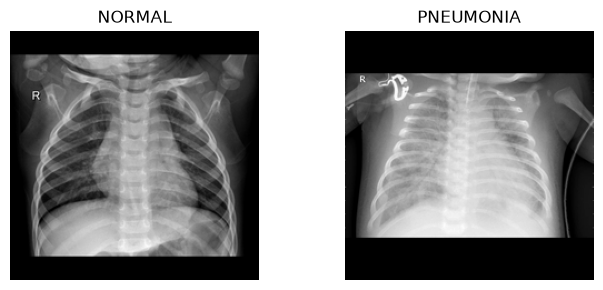

In [2]:
def load_split(name):
    with np.load(DATA_DIR / f"{name}.npz") as data:
        images = data["images"]   # uint8: (N,224,224), memory efficient
        labels = data["labels"].astype("int32")
    assert images.ndim == 3 and images.shape[1:] == (224, 224)
    assert set(np.unique(labels)).issubset({0, 1})
    return images, labels

X_train, y_train = load_split("train")
X_val, y_val = load_split("validation")
print("Train:", X_train.shape, X_train.dtype, np.unique(y_train, return_counts=True))
print("Validation:", X_val.shape, X_val.dtype, np.unique(y_val, return_counts=True))

plt.figure(figsize=(7, 3))
for i, idx in enumerate([np.flatnonzero(y_train == 0)[0], np.flatnonzero(y_train == 1)[0]]):
    plt.subplot(1, 2, i + 1)
    plt.imshow(X_train[idx], cmap="gray")
    plt.title("NORMAL" if i == 0 else "PNEUMONIA")
    plt.axis("off")
plt.tight_layout()
plt.show()

## 3. Build ResNet50 data pipelines

ResNet50 pretrained on ImageNet expects **3-channel images** with a specific preprocessing convention (RGB→BGR and channel mean subtraction). We repeat each grayscale channel three times **per batch**, and call `resnet50.preprocess_input`. **Do not divide by 255 first.**

**Note:** The saved model below expects **preprocessed 3-channel** inputs. Use the same `prepare_batch` function at prediction time.

In [3]:
AUTOTUNE = tf.data.AUTOTUNE

def prepare_batch(images, labels):
    images = tf.cast(images, tf.float32)        # original pixel range: 0..255
    images = tf.expand_dims(images, axis=-1)   # (B,224,224,1)
    images = tf.repeat(images, repeats=3, axis=-1)  # (B,224,224,3)
    images = tf.keras.applications.resnet50.preprocess_input(images)
    return images, tf.cast(labels, tf.float32)

def make_dataset(images, labels, training=False):
    ds = tf.data.Dataset.from_tensor_slices((images, labels))
    if training:
        ds = ds.shuffle(min(len(images), 2000), seed=SEED, reshuffle_each_iteration=True)
    ds = ds.batch(BATCH_SIZE).map(prepare_batch, num_parallel_calls=AUTOTUNE)
    return ds.prefetch(1)  # avoid aggressive memory prefetch

train_ds = make_dataset(X_train, y_train, training=True)
val_ds = make_dataset(X_val, y_val)
for xb, yb in train_ds.take(1):
    print("Batch:", xb.shape, "Labels:", yb.shape, "Input pixel range:", float(tf.reduce_min(xb)), float(tf.reduce_max(xb)))

Batch: (8, 224, 224, 3) Labels: (8,) Input pixel range: -123.68000030517578 151.06100463867188


## 4. Define ResNet50 with pretrained ImageNet weights

In [4]:
# First run requires internet to download ImageNet weights into Keras cache.
backbone = keras.applications.ResNet50(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3),
)
backbone.trainable = False

inputs = keras.Input(shape=(224, 224, 3), name="preprocessed_xray")
x = backbone(inputs, training=False)  # keep BatchNorm stable during fine-tuning
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.35)(x)
outputs = layers.Dense(1, activation="sigmoid", name="pneumonia_probability")(x)
resnet_model = keras.Model(inputs, outputs, name="resnet50_pneumonia")

resnet_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss="binary_crossentropy",
    metrics=[keras.metrics.BinaryAccuracy(name="accuracy"), keras.metrics.AUC(name="auc")],
)
resnet_model.summary(show_trainable=True)

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 4s 0us/step


Model: "resnet50_pneumonia"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━┓
┃ Layer (type)                ┃ Output Shape          ┃    Param # ┃ Trai… ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━┩
│ preprocessed_xray           │ (None, 224, 224, 3)   │          0 │   -   │
│ (InputLayer)                │                       │            │       │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ resnet50 (Functional)       │ (None, 7, 7, 2048)    │ 23,587,712 │   N   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ global_average_pooling2d    │ (None, 2048)          │          0 │   -   │
│ (GlobalAveragePooling2D)    │                       │            │       │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ dropout (Dropout)           │ (None, 2048)          │          0 │   -   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ pneumonia_probability       │ (None, 1)             │      2,049 │   Y   │
│ (Dense)                     │                       │            │       │
└─────────────────────────────┴───────────────────────┴────────────┴───────┘

 Total params: 23,589,761 (89.99 MB)

 Trainable params: 2,049 (8.00 KB)

 Non-trainable params: 23,587,712 (89.98 MB)

## 5. Calculate class weights and train the classification head

In [5]:
weights = compute_class_weight(class_weight="balanced", classes=np.array([0,1]), y=y_train)
class_weights = {0: float(weights[0]), 1: float(weights[1])}
print("Class weights:", class_weights)

model_path = MODEL_DIR / "resnet50_transfer.keras"
def callbacks():
    return [
        keras.callbacks.ModelCheckpoint(model_path, monitor="val_auc", mode="max", save_best_only=True, verbose=1),
        keras.callbacks.EarlyStopping(monitor="val_auc", mode="max", patience=3, restore_best_weights=True),
        keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, min_lr=1e-6),
    ]

history_head = resnet_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=HEAD_EPOCHS,
    class_weight=class_weights,
    callbacks=callbacks(),
    verbose=1,
)
print("Saved best checkpoint:", model_path.exists())

Class weights: {0: 1.9338575393154487, 1: 0.6743548387096774}
Epoch 1/8


/Users/prernamallawat/Desktop/Albany/Fall 2026/AI/Medical-Image-Classification/.venv/lib/python3.13/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


523/523 ━━━━━━━━━━━━━━━━━━━━ 0s 269ms/step - accuracy: 0.9141 - auc: 0.9740 - loss: 0.2009
Epoch 1: val_auc improved from None to 0.99075, saving model to /Users/prernamallawat/Desktop/Albany/Fall 2026/AI/Medical-Image-Classification/models/resnet50_transfer.keras

Epoch 1: finished saving model to /Users/prernamallawat/Desktop/Albany/Fall 2026/AI/Medical-Image-Classification/models/resnet50_transfer.keras
523/523 ━━━━━━━━━━━━━━━━━━━━ 183s 344ms/step - accuracy: 0.9141 - auc: 0.9740 - loss: 0.2009 - val_accuracy: 0.9401 - val_auc: 0.9908 - val_loss: 0.1463 - learning_rate: 0.0010
Epoch 2/8
523/523 ━━━━━━━━━━━━━━━━━━━━ 0s 297ms/step - accuracy: 0.9440 - auc: 0.9880 - loss: 0.1340
Epoch 2: val_auc improved from 0.99075 to 0.99338, saving model to /Users/prernamallawat/Desktop/Albany/Fall 2026/AI/Medical-Image-Classification/models/resnet50_transfer.keras

Epoch 2: finished saving model to /Users/prernamallawat/Desktop/Albany/Fall 2026/AI/Medical-Image-Classification/models/resnet50_trans

## 6. Optional fine-tuning

If the first training stage completes, you may set `RUN_FINE_TUNING=True` in Cell 1 and rerun all cells. Fine-tuning uses a much smaller learning rate and only trains upper backbone layers, keeping BatchNorm frozen. **The GPU is optional**; CPU training is slower.

In [6]:
history_fine = None
if RUN_FINE_TUNING:
    backbone.trainable = True
    for layer in backbone.layers[:-30]:
        layer.trainable = False
    for layer in backbone.layers:
        if isinstance(layer, layers.BatchNormalization):
            layer.trainable = False

    resnet_model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=1e-5),
        loss="binary_crossentropy",
        metrics=[keras.metrics.BinaryAccuracy(name="accuracy"), keras.metrics.AUC(name="auc")],
    )
    history_fine = resnet_model.fit(
        train_ds,
        validation_data=val_ds,
        epochs=FINE_TUNE_EPOCHS,
        class_weight=class_weights,
        callbacks=callbacks(),
        verbose=1,
    )
else:
    print("Fine-tuning skipped; head-only transfer learning completed.")

Fine-tuning skipped; head-only transfer learning completed.


## 7. Plot learning curves

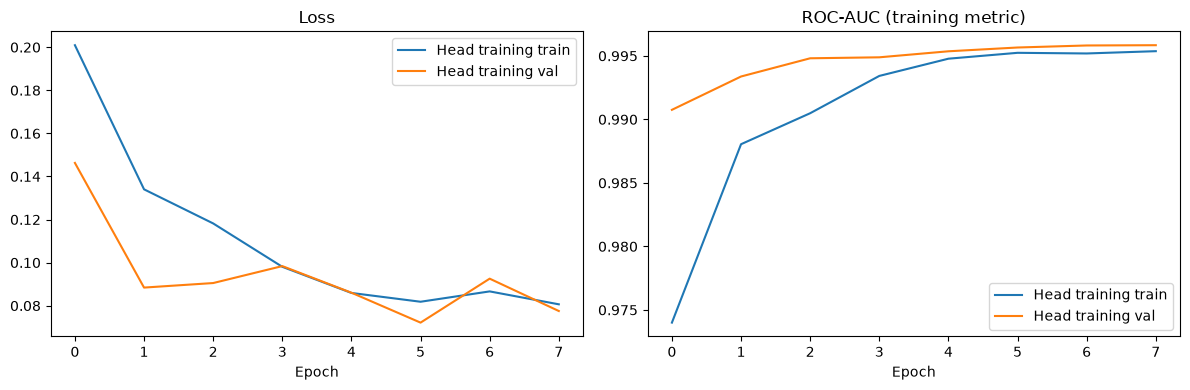

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for history, label in [(history_head, "Head training"), (history_fine, "Fine-tuning")]:
    if history is None:
        continue
    axes[0].plot(history.history["loss"], label=f"{label} train")
    axes[0].plot(history.history["val_loss"], label=f"{label} val")
    axes[1].plot(history.history["auc"], label=f"{label} train")
    axes[1].plot(history.history["val_auc"], label=f"{label} val")
axes[0].set_title("Loss")
axes[1].set_title("ROC-AUC (training metric)")
for ax in axes:
    ax.set_xlabel("Epoch")
    ax.legend()
plt.tight_layout()
plt.savefig(RESULTS_DIR / "resnet50_learning_curves.png", dpi=150)
plt.show()

## 8. Evaluate on validation only

Threshold `0.5` is the default; a second threshold is selected *only from validation predictions*, aiming for **at least 95% specificity**. Validation threshold selection can be optimistic. Do not treat these as independent test results.

In [8]:
best_resnet = keras.models.load_model(model_path)
val_prob = best_resnet.predict(val_ds, verbose=1).ravel()
val_pred = (val_prob >= 0.5).astype(int)

print("Validation ROC-AUC:", round(roc_auc_score(y_val, val_prob), 4))
print("Accuracy at threshold 0.5:", round(accuracy_score(y_val, val_pred), 4))
print("Confusion matrix (0.5):", confusion_matrix(y_val, val_pred, labels=[0,1]))
print(classification_report(y_val, val_pred, labels=[0,1], target_names=["NORMAL","PNEUMONIA"], zero_division=0))

fpr, tpr, thresholds = roc_curve(y_val, val_prob)
specificity = 1 - fpr
eligible = np.where(specificity >= 0.95)[0]
# Among eligible points, prefer finite threshold; at least one finite point if the classes are present.
eligible_finite = eligible[np.isfinite(thresholds[eligible])]
if len(eligible_finite):
    idx = eligible_finite[np.argmax(tpr[eligible_finite])]
    chosen_threshold = float(thresholds[idx])
    print("Threshold at >=95% validation specificity:", round(chosen_threshold,4))
    print("Sensitivity:", round(float(tpr[idx]),4), "Specificity:", round(float(specificity[idx]),4))
else:
    chosen_threshold = 0.5
    print("No finite ROC threshold found that satisfies the target; using 0.5.")

summary = pd.DataFrame([{
    "Model":"ResNet50 transfer learning",
    "Validation AUC":roc_auc_score(y_val,val_prob),
    "Accuracy at 0.5":accuracy_score(y_val,val_pred),
    "Selected threshold":chosen_threshold,
    "Sensitivity":float(tpr[idx]) if len(eligible_finite) else np.nan,
    "Specificity":float(specificity[idx]) if len(eligible_finite) else np.nan,
}])
display(summary.round(4))
summary.to_csv(RESULTS_DIR / "resnet50_validation_metrics.csv", index=False)
pd.DataFrame({"label":y_val, "pneumonia_probability":val_prob}).to_csv(RESULTS_DIR / "resnet50_validation_predictions.csv", index=False)

132/132 ━━━━━━━━━━━━━━━━━━━━ 52s 391ms/step
Validation ROC-AUC: 0.9959
Accuracy at threshold 0.5: 0.9762
Confusion matrix (0.5): [[261   7]
 [ 18 765]]
              precision    recall  f1-score   support

      NORMAL       0.94      0.97      0.95       268
   PNEUMONIA       0.99      0.98      0.98       783

    accuracy                           0.98      1051
   macro avg       0.96      0.98      0.97      1051
weighted avg       0.98      0.98      0.98      1051

Threshold at >=95% validation specificity: 0.3234
Sensitivity: 0.986 Specificity: 0.9552


,Model,Validation AUC,Accuracy at 0.5,Selected threshold,Sensitivity,Specificity
0,ResNet50 transfer learning,0.9959,0.9762,0.3234,0.986,0.9552


## 9. Verify files and next steps

Your results are saved under `models/` and `results/`. The next notebook should compare **Dense**, **CNN**, and **ResNet50** under the same validation protocol. After checking the patient-disjoint split, create a separate **test-only** evaluation notebook. For external validation, NIH and Kaggle have different populations and label definitions, which must be explicitly accounted for.

In [9]:
for path in [model_path, RESULTS_DIR / "resnet50_learning_curves.png", RESULTS_DIR / "resnet50_validation_metrics.csv", RESULTS_DIR / "resnet50_validation_predictions.csv"]:
    print(path.relative_to(PROJECT_DIR), "✅" if path.exists() else "MISSING")
print("Done: ResNet50 validation. Test set remains untouched.")

models/resnet50_transfer.keras ✅
results/resnet50_learning_curves.png ✅
results/resnet50_validation_metrics.csv ✅
results/resnet50_validation_predictions.csv ✅
Done: ResNet50 validation. Test set remains untouched.
